### Sorbonne Université, Faculté des Sciences et Ingénierie, 2021-2022
### Licence de Mathématiques, Analyse numérique ( LU3MA232)

---

<center> <h1>TP1 : Approximation d'un problème de Cauchy</h1> </center>

---

In [2]:
# import Python 
import numpy as np
import matplotlib.pyplot as plt

## Exercice 1 - Rappels de `Python` et cas d'un exercice du TD1 

Dans cet exercice nous allons reprendre l'exercice 6 du TD1. Soit $T>0$, on considère ainsi le problème de Cauchy ci-dessous : 
$$(P_1)
\begin{cases}
y'(t)= - 10 ( y(t) - t^2 ) + 2t~,~ 0<t<T~, \\
y(0) = 0.
\end{cases}
$$

On a vu que la solution est la fonction $y(t) =t^2$. Dans la suite on prendra $T=1$.

**Q1)** Coder une routine `Python` pour cette solution.

In [8]:
def Sol(t) :
    return t**2

On souhaite à présent représenter graphiquement la solution. Plusieurs étapes sont nécessaires:

- Construire une discrétisation $(t_n)_{n\ge0}$ de l'intervalle $[0,T]$ : pour $N \in \mathbb{N}^*$, on pose $h=\frac{T}{N}$, et on définit $t_n = nh$ pour $n=0,\ldots,N$.

- Evaluer la fonction aux différents temps de discrétisation : $y(t_n)$ pour $n \ge 0$.

- Afficher la ligne brisée des points $(t_n, y(t_n))_{n \ge 0}$.

- Ajouter de l'information au graphique pour faciliter la lecture (*légende, titre,*...).

***Remarque:*** Notez que plus la discrétisation est fine plus la courbe est lisse (aspect "continu"). En revanche, en pratique, une discrétisation trop fine pourra induire des temps de calculs très longs.

**Q2)** Tracer sur un même graphique la solution pour les deux discrétisations suivantes : $N \in \{ 5, 20 \}$.

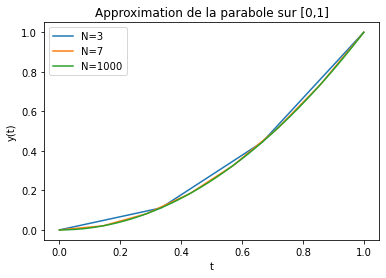

In [14]:
for N in [3,7,1000] :
    X = np.linspace(0,1,N+1)
    Y = [Sol(t) for t in X]
    plt.plot(X,Y,label="N="+str(N))

plt.xlabel('t')
plt.ylabel('y(t)')
plt.legend() # Affiche le nom des courbes (label dans plot)
plt.title('Approximation de la parabole sur [0,1]')
plt.show()

On se propose de résoudre numériquement le problème $(P_1)$ par la méthode d'Euler explicite. On cherche ainsi à calculer une suite de valeurs $(y_n)_{0 \le n \le N}$ tel que $y_n$ approche $y(t_n)$. Nous avons vu en TD que, dans le cas présent, la méthode s'écrit :
$$(E_1)
\begin{cases}
y_{n+1} = (1-10h) y_n + 2 n h^2 ( 1 + 5 n h)~,~ n = 0, \dots, N-1, \\
y_0 = 0.
\end{cases}
$$

**Q3)** Coder une routine `Python` qui prend en paramètre d'entrée la valeur de $N$ et qui retourne en sortie les temps discrets $(t_n)_{0 \le n \le N}$ (*on a toujours $t_n = nh$ et $h=T/N$*) ainsi que les valeurs $(y_n)_{0 \le n \le N}$ données par $(E_1)$.

In [20]:
def Euler(N) :
    h = 1/N
    Temps = [n*h for n in range(N+1)]
    Approx = [0] # On initialise y_0 = 0
    for n in range(0,N) :
        yn = Approx[-1] # Affecter à yn le dernier élément de la liste
        z = (1-10*h)*yn + 2*n*(h**2)*(1+5*n*h) # z = y_{n+1}
        Approx.append(z) # Ajoute z en fin de liste
        # Approx = [Approx, z]
    return Temps, Approx

[0,
 0.0,
 0.16000000000000003,
 0.32000000000000006,
 0.6400000000000001,
 0.9600000000000002]

**Q4)** Représenter sur un même graphique :
- la solution continue $y(t)$ sur $[0,T]$ (*de façon suffisamment "lisse"*),
- les valeurs $(t_n,y_n)_{0 \le n \le N}$ du schéma $(E_1)$ pour $N \in \{ 5, 20 \}$.

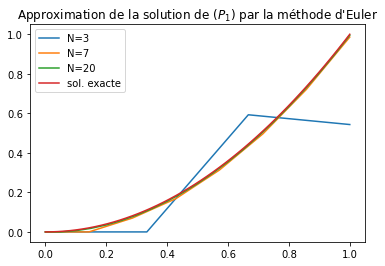

In [26]:
for N in [3,7,20] :
    X, Y = Euler(N)
    plt.plot(X,Y,label='N='+str(N))

I = np.linspace(0,1,50)
S = [Sol(t) for t in I]
plt.plot(I,S,label='sol. exacte')


plt.legend()
plt.title("Approximation de la solution de ($P_1$) par la méthode d'Euler")
plt.show()

**Q5)** La schéma d'Euler explicite est connu pour être une méthode d'ordre 1. Nous allons le vérifier numériquement.
- Déclarer un tableau contenant différentes valeurs de $N = [8, 16, 32, 64, 128]$.
- Pour chaque valeur de $N$, calculer :
    - le tableau des temps discrets, $(t_n)_{n\ge 0}$,
    - le schéma d'Euler explicite $(E_1)$, $(y_n)_{n\ge 0}$,
    - la solution exacte aux temps discrets, $(y(t_n))_{n\ge 0}$,
    - le pas $h=\frac{T}{N}$ et l'erreur $e_h$, associés à cette discrétisation, sans oublier de stocker ces valeurs et avec,
        $$e_h = \max_{0\le n \le N}(|y(t_n)-y_n)|).$$
- Représenter sur un graphique l'erreur $e_h$ en fonction de $h$ avec une échelle logarithmique sur les deux axes. En effet, si $e_h \sim C h^p$, en passant en échelle logarithmique, on a  $\log(e_h) \sim p \log(h) + \log(C)$. Les résultats du TD ont permis d'estimer que $p=1$ et $C \simeq \frac{1}{10}$ pour $h$ *"suffisamment petit"*.

Text(0.5, 1.0, "Graphe de l'erreur en fonction du pas de temps, échelle log-log")

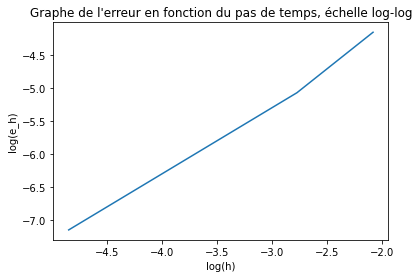

In [30]:
Lh =[]
Leh =[]
for N in [8,16,32,64,128] :
    Temps, Approx = Euler(N)
    Temps = np.array(Temps) # Traduit la liste liste Python en liste numpy (pour permettre la soustraction de listes)
    Solution = np.array([Sol(t) for t in Temps]) # Calcul de la solution exactes aux points de Temps
    erreurh = max(abs(Approx-Solution)) # Calcul le maximum de la liste des différences |yn-y(t_n)|
    Lh.append(np.log(1/N))
    Leh.append(np.log(erreurh))
plt.plot(Lh,Leh)

plt.xlabel('log(h)')
plt.ylabel('log(e_h)')
plt.title("Graphe de l'erreur en fonction du pas de temps, échelle log-log")

**Q6)** Reprendre les questions **Q3)** et **Q5** pour le second problème de l'exercice 6 du TD1, à savoir le problème de Cauchy: 
$$(P_2)
\begin{cases}
y'(t)= 10 ( y(t) - t^2 ) + 2t~,~ 0<t<T~, \\
y(0) = 0.
\end{cases}
$$
Dont la solution est toujours la fonction $y(t) =t^2$. La méthode d'Euler explicite donne ici :
$$(E_2)
\begin{cases}
y_{n+1} = (1+10h) y_n + 2 n h^2 ( 1 - 5 n h)~,~ n = 0, \dots, N-1, \\
y_0 = 0.
\end{cases}
$$
On avait noté que l'erreur $e_h$ se comportait également en $C h^p$ avec toujours $p=1$ mais ici avec $C \simeq \frac{e^{10 T}}{10}$. Arrivez-vous à retrouver graphiquement ce résultat ? Il ne faut pas hésiter à rendre $h$ *"suffisamment petit"*.

## Exercice 2 - Chute d'un objet

### I. Modélisation du phénomène

Dans cet exercice, nous nous intéressons au problème de mécanique suivant : la chute d'un corps de masse $m$, initialement lancé à la vitesse $v_{\mathrm{init}}$, sous l'effet d'un champ gravitationnel $g$ (qu'on supposera constant). Si la chute se produit dans l'air ambiant, on pourra négliger la poussée d'Archimède, mais pas la force de frottement liée à la vitesse $v$ du corps. On suppose que les forces de frottements peuvent se mettre sous la forme : $\vec{F} = - \alpha v$, s'opposant ainsi au mouvement. Le second principe de la dynamique nous donne alors :
$$(C)
\begin{cases}
m v'(t) = m g - \alpha v(t) ~,~ 0<t<T ~, \\
v(0) = v_{\mathrm{init}}.
\end{cases}
$$
où $T>0$ correspond au temps final d'étude du mouvement de chute. On peut montrer que la solution au problème $(C)$ est donnée par :
$$
v(t) = \frac{m g}{\alpha} \left(1-e^{-\dfrac{\alpha}{m}t} \right) + v_{\mathrm{init}} e^{-\dfrac{\alpha}{m}t}.
$$
On prendra les valeurs numériques suivantes :
- $T  =  2$ [$s$]
- $v_{\mathrm{init}} = 0.2$ [$m/s$]
- $m = 1$  [$kg$]
- $g = 9.81$ [$m/s^2$]

**Q1)** Coder la fonction solution en `Python`. Puis tracer cette solution pour $\alpha \in \{ 0.1, 1, 10\}$ [$kg/s$] afin de visualiser l'effet du frottement.

** Attention :** dans toute la suite on prendra $\alpha = 3$ [$kg/s$].

### II. Schéma d'Euler explicite

On souhaite approcher le problème $(C)$ par la méthode d'Euler explicite et réaliser une étude de convergence.

**Q2)** Déterminer la fonction $f:[0,T]\times\mathbb{R} \rightarrow \mathbb{R}$ telle que le problème $(C)$ se réécrive sous la forme : 
$$(P)
\begin{cases}
v'(t) = f(t,v(t)) ~,~ 0<t<T ~, \\
v(0) = v_{\mathrm{init}}.
\end{cases}
$$

Nous allons rappeler la méthode d'Euler explicite pour approcher le problème $(P)$. Soit $N \in \mathbb{N}^*$, on introduit les temps discrets $t_n = n h$, $n=0,1,\ldots, N$ avec  $h = \frac{T}{N}$. La méthode  consiste à trouver une suite de valeurs $v_n$ approchant les valeurs $v(t_n)$, pour tout $n=0,1,\ldots, N$. On aura :
$$(EE)
\begin{cases}
v_{n+1} = v_n + h \, f(t_n,v_n) ~,~ n=0,1,\ldots, N-1, \\
v_0 = v_{\mathrm{init}}.
\end{cases}
$$
Nous allons reprendre la stratégie d'étude numérique de l'exercice précédent. 

**Q3)** Coder les actions suivantes :
1. La méthode d'Euler explicite $(EE)$ afin d'approcher $(C)$. *On pourra choisir de coder une méthode d'Euler "générique" prenant $f$ en entrée ou bien particularisée au cas d'étude*.
2. Sur un même graphique, représenter la solution exacte et la solution approchée par le schéma $(EE)$ pour $N=25$.
3. Calculer l'erreur du schéma $(EE)$ pour $N = [25, 50, 100, 200]$ et représenter graphiquement cette erreur afin de vérifier qu'on retrouve l'ordre 1.

### II. Schéma d'Euler modifié

On reprend le schéma d'Euler modifié, vu en cours, pour le problème $(P)$. En réutilisant les mêmes notations que ci-dessus, on aura :
$$(EM)
\begin{cases}
v_{n+1} = v_n + h \, f\left(t_{n} + \frac{h}{2}, y_{n} + \frac{h}{2} f(t_{n}, y_{n} ) \right)~,~ n=0,1,\ldots, N-1,  \\
v_0 = v_{\mathrm{init}}.
\end{cases}
$$

**Q4)** Reprendre la question **Q3)** pour ce schéma, cette fois-ci on devra retrouver l'ordre 2.

### III. Schéma d'Euler implicite

Pour finir on regarde la méthode d'Euler implicite pour approcher le problème $(P)$. En réutilisant les mêmes notations que ci-dessus, on aura :
$$(EI)
\begin{cases}
v_{n+1} = v_n + h \, f(t_{n+1},v_{n+1}) ~,~ n=0,1,\ldots, N-1, \\
v_0 = v_{\mathrm{init}}.
\end{cases}
$$

**Q5)** Reprendre la question **Q3)** pour le schéma d'Euler implicite.